# CS-681 Project: Audio Result Figures
Runs on CPU. Attach the output of the STCS-Speech notebook as input.

In [1]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Find the per-clip results file from the speech notebook
paths = glob.glob("/kaggle/input/**/audio_results.csv", recursive=True)
print("Found:", paths)
res = pd.read_csv(paths[0])
print(res.shape)
print(res.columns.tolist())

Found: ['/kaggle/input/notebooks/sawsannoli/stcs-speech/audio_results.csv']
(250, 12)
['image', 'true_grade', 'pred_grade', 'summary', 'tts_text', 'audio_path', 'duration_s', 'gen_time_s', 'rtf', 'transcript', 'wer', 'utmos']


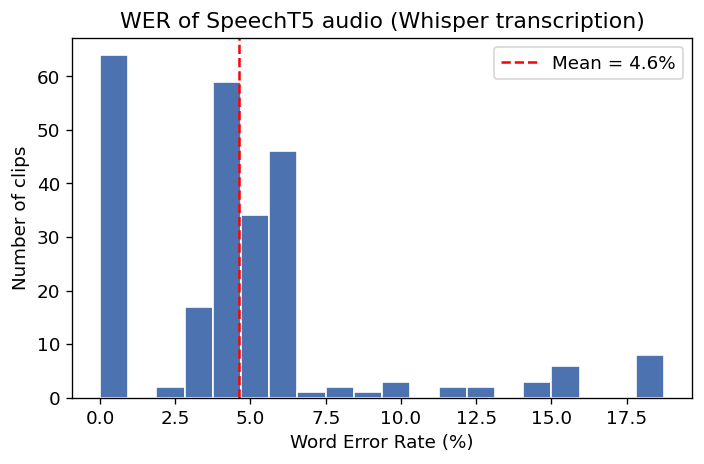

In [2]:
OUT = "/kaggle/working"
plt.rcParams.update({"font.size": 11, "figure.dpi": 120})

# Figure 1: distribution of WER across all clips
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(res["wer"] * 100, bins=20, color="#4C72B0", edgecolor="white")
ax.axvline(res["wer"].mean() * 100, color="red", linestyle="--",
           label=f"Mean = {res['wer'].mean() * 100:.1f}%")
ax.set_xlabel("Word Error Rate (%)"); ax.set_ylabel("Number of clips")
ax.set_title("WER of SpeechT5 audio (Whisper transcription)")
ax.legend()
plt.tight_layout(); plt.savefig(f"{OUT}/fig_wer_hist.png", dpi=200); plt.show()

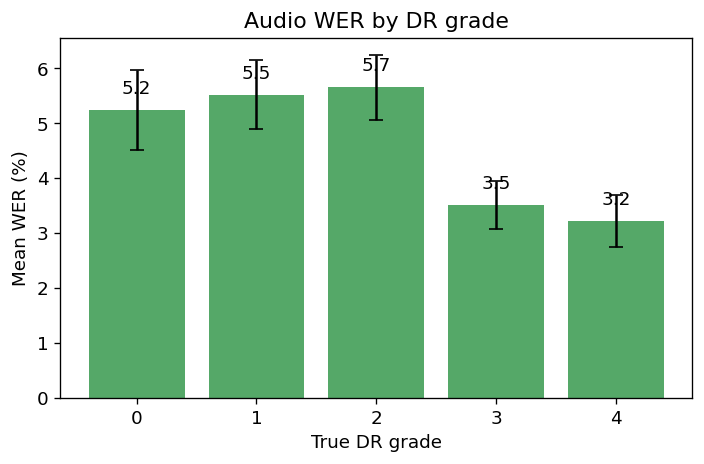

In [3]:
# Figure 2: mean WER per true DR grade (with standard error bars)
g = res.groupby("true_grade")["wer"].agg(["mean", "sem"]) * 100
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(g.index.astype(str), g["mean"], yerr=g["sem"], capsize=4, color="#55A868")
for x, v in zip(range(len(g)), g["mean"]):
    ax.text(x, v + 0.3, f"{v:.1f}", ha="center")
ax.set_xlabel("True DR grade"); ax.set_ylabel("Mean WER (%)")
ax.set_title("Audio WER by DR grade")
plt.tight_layout(); plt.savefig(f"{OUT}/fig_wer_by_grade.png", dpi=200); plt.show()

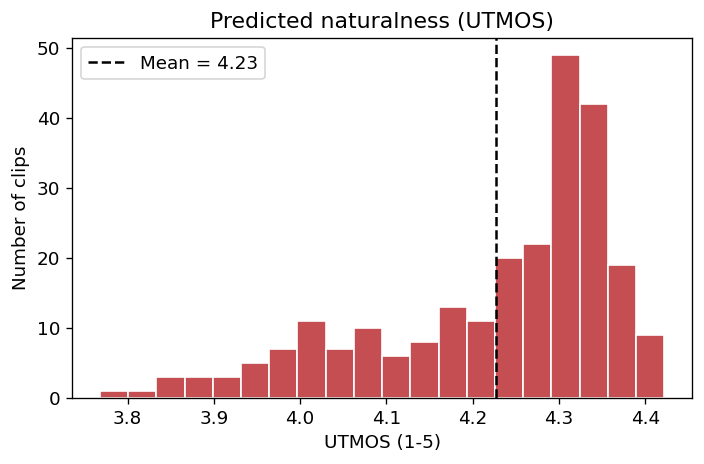

In [4]:
# Figure 3: UTMOS naturalness distribution (only if the column exists)
if "utmos" in res.columns:
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.hist(res["utmos"], bins=20, color="#C44E52", edgecolor="white")
    ax.axvline(res["utmos"].mean(), color="black", linestyle="--",
               label=f"Mean = {res['utmos'].mean():.2f}")
    ax.set_xlabel("UTMOS (1-5)"); ax.set_ylabel("Number of clips")
    ax.set_title("Predicted naturalness (UTMOS)")
    ax.legend()
    plt.tight_layout(); plt.savefig(f"{OUT}/fig_utmos_hist.png", dpi=200); plt.show()
else:
    print("No utmos column found")

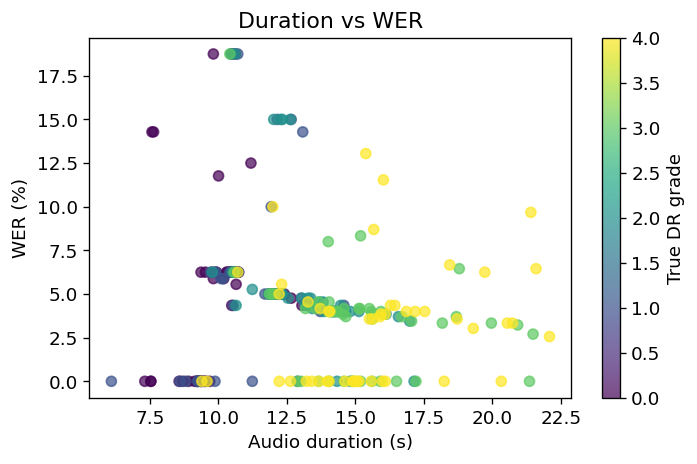

Correlation (duration, WER): -0.156


In [5]:
# Figure 4: audio duration vs WER (do longer summaries get transcribed better?)
if "duration_s" in res.columns:
    fig, ax = plt.subplots(figsize=(6, 4))
    sc = ax.scatter(res["duration_s"], res["wer"] * 100, c=res["true_grade"], cmap="viridis", alpha=0.7)
    plt.colorbar(sc, label="True DR grade")
    ax.set_xlabel("Audio duration (s)"); ax.set_ylabel("WER (%)")
    ax.set_title("Duration vs WER")
    plt.tight_layout(); plt.savefig(f"{OUT}/fig_duration_vs_wer.png", dpi=200); plt.show()
    print("Correlation (duration, WER):", round(res["duration_s"].corr(res["wer"]), 3))

In [6]:
# Summary table for the paper
cols = [c for c in ["duration_s", "rtf", "wer", "utmos"] if c in res.columns]
summary = res[cols].agg(["mean", "std", "min", "max"]).T.round(3)
summary.to_csv(f"{OUT}/audio_summary_table.csv")
print(summary)

              mean    std    min     max
duration_s  13.002  3.063  6.100  22.080
rtf          0.188  0.003  0.180   0.204
wer          0.046  0.042  0.000   0.188
utmos        4.227  0.142  3.768   4.422
